# 04 · Explainability & Subgroup Analysis

A good risk model should be **accurate, calibrated and understandable**. This notebook explains *why* the model predicts what it does, at global and individual level, and checks that performance holds across patient subgroups.

* **Logistic regression odds ratios** — a transparent reference model.
* **Permutation importance** — model-agnostic, on the original predictors.
* **SHAP** — global and local explanations of the gradient-boosting model.
* **Subgroup performance** — by gender, age group and BMI category.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(PROJECT_ROOT))

import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_columns", 30)

from src.config import FIGURES_DIR, MODELS_DIR, REPORTS_DIR, TARGET
from src.evaluation import save_fig

In [2]:
import json
import joblib
import shap

from src.data_preparation import prepare_dataset, split_data, add_clinical_bins
from src.evaluation import compute_metrics
from src.explainability import logistic_odds_ratios, permutation_importance_table, shap_explanation

df = prepare_dataset()
X_train, X_val, X_test, y_train, y_val, y_test = split_data(df)

final_model = joblib.load(MODELS_DIR / "final_model.joblib")
tree_pipeline = joblib.load(MODELS_DIR / "best_pipeline_uncalibrated.joblib")
lr_pipeline = joblib.load(MODELS_DIR / "logistic_regression.joblib")
summary = json.loads((REPORTS_DIR / "metrics.json").read_text())
THRESHOLD = summary["screening_threshold"]
p_test = final_model.predict_proba(X_test)[:, 1]
print(summary["best_model"], "| screening threshold:", THRESHOLD)

Gradient Boosting (class-weighted) + isotonic calibration | screening threshold: 0.1278


## 1. Logistic regression odds ratios

Continuous features are standardised, so each odds ratio is the multiplicative change in the odds of diabetes for a **one-standard-deviation increase**, holding the other features fixed. Interaction terms (`glucose_hba1c`, `age_bmi`) overlap heavily with their components, so individual signs should be read cautiously — they are *partial* effects, not clinical causal claims.

In [3]:
odds = logistic_odds_ratios(lr_pipeline)
odds

,feature,coefficient,odds_ratio
0,HbA1c_level,5.2196,184.8585
1,blood_glucose_level,3.5384,34.4120
2,glucose_hba1c,-2.4983,0.0822
3,prediabetes_flag,1.5305,4.6207
4,hypertension,0.7270,2.0689
5,heart_disease,0.6554,1.9260
6,smoking_history_no info,-0.6129,0.5418
7,age_bmi,0.5552,1.7424
8,age,0.5460,1.7264
9,bmi,0.3725,1.4513


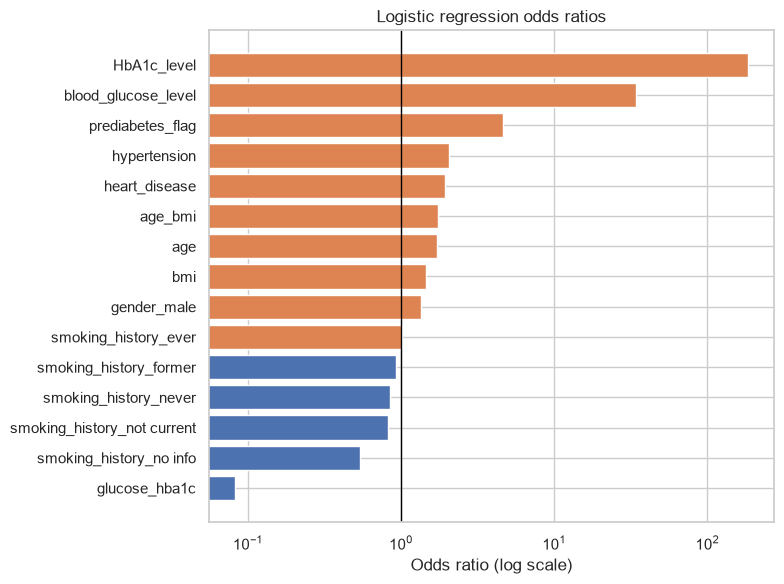

In [4]:
fig, ax = plt.subplots(figsize=(8, 6))
o = odds.sort_values("coefficient")
ax.barh(o["feature"], o["odds_ratio"], color=np.where(o["coefficient"] > 0, "#DD8452", "#4C72B0"))
ax.axvline(1, color="black", lw=1)
ax.set_xscale("log")
ax.set(xlabel="Odds ratio (log scale)", title="Logistic regression odds ratios")
fig.tight_layout()
save_fig(fig, FIGURES_DIR / "lr_odds_ratios.png");

## 2. Permutation importance (test set)

How much does test PR-AUC drop when each **original** predictor is randomly shuffled? This is model-agnostic and measured on unseen data.

,feature,importance_mean,importance_std
0,glucose_hba1c,0.3964,0.0107
1,HbA1c_level,0.3896,0.0052
2,blood_glucose_level,0.1194,0.0056
3,age_bmi,0.0487,0.0059
4,bmi,0.0061,0.0020
5,smoking_history,0.0046,0.0005
6,age,0.0035,0.0009
7,hypertension,0.0023,0.0004
8,heart_disease,0.0019,0.0005
9,prediabetes_flag,-0.0001,0.0000


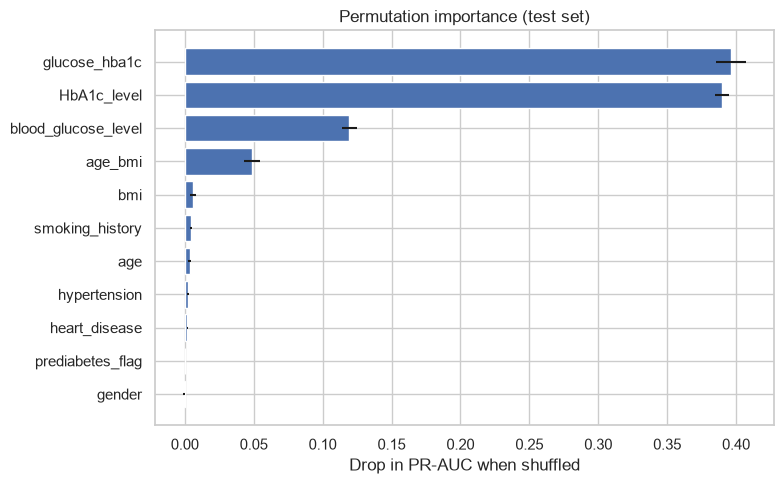

In [5]:
perm = permutation_importance_table(final_model, X_test, y_test, n_repeats=5)
fig, ax = plt.subplots(figsize=(8, 5))
p = perm.sort_values("importance_mean")
ax.barh(p["feature"], p["importance_mean"], xerr=p["importance_std"], color="#4C72B0")
ax.set(xlabel="Drop in PR-AUC when shuffled", title="Permutation importance (test set)")
fig.tight_layout()
save_fig(fig, FIGURES_DIR / "permutation_importance_test.png")
perm

## 3. SHAP explanations

SHAP values decompose each prediction into additive contributions from each feature (in log-odds units). They are computed on the uncalibrated gradient-boosting pipeline; isotonic calibration is a monotonic re-mapping of its scores, so the ranking and the direction of each feature's effect are unchanged.

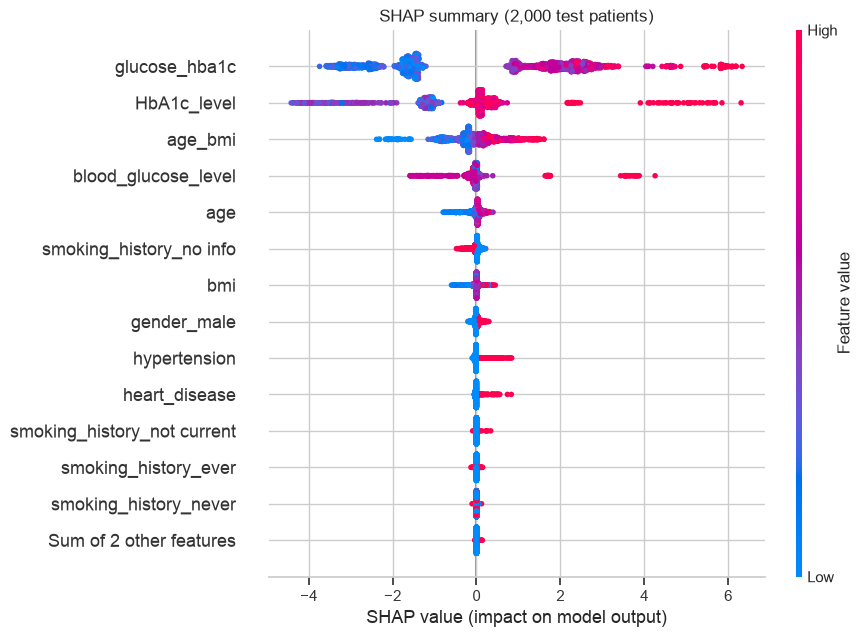

In [6]:
X_explain = X_test.sample(2000, random_state=42)
sv = shap_explanation(tree_pipeline, X_train, X_explain)

shap.plots.beeswarm(sv, max_display=14, show=False)
plt.title("SHAP summary (2,000 test patients)")
save_fig(plt.gcf(), FIGURES_DIR / "shap_summary.png")
plt.show()

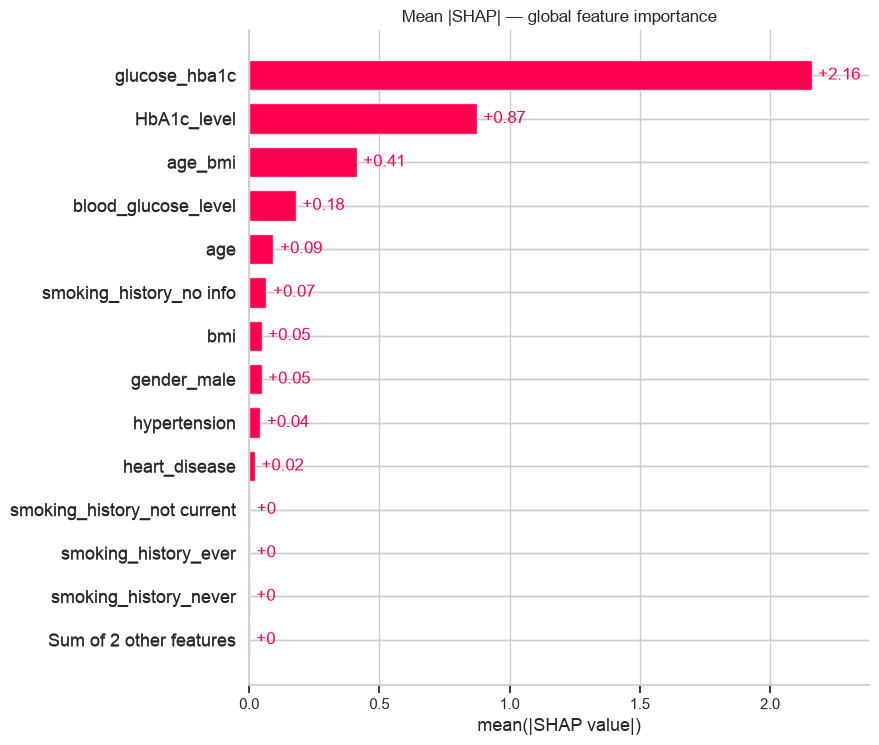

In [7]:
shap.plots.bar(sv, max_display=14, show=False)
plt.title("Mean |SHAP| — global feature importance")
save_fig(plt.gcf(), FIGURES_DIR / "shap_global_importance.png")
plt.show()

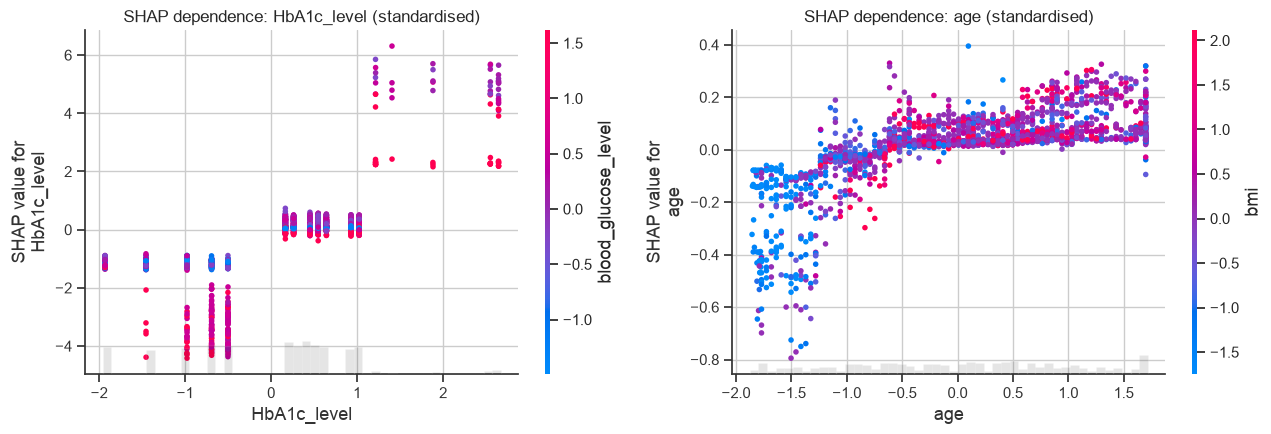

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, feat in zip(axes, ["HbA1c_level", "age"]):
    shap.plots.scatter(sv[:, feat], color=sv[:, "blood_glucose_level"] if feat == "HbA1c_level" else sv[:, "bmi"],
                       ax=ax, show=False)
    ax.set_title(f"SHAP dependence: {feat} (standardised)")
fig.tight_layout()
save_fig(fig, FIGURES_DIR / "shap_dependence.png");

**Reading the SHAP plots**

* **Glycaemic markers dominate.** The engineered `glucose_hba1c` interaction is the single most influential feature, followed by `HbA1c_level` itself; together with glucose they account for most of the model's output — matching permutation importance.
* The HbA1c dependence plot shows **step changes at the clinical thresholds**: low values push strongly towards "no diabetes" and values ≥ ~6.6% push strongly towards "diabetes" — the model has learned the diagnostic cut-offs.
* **Age and BMI** act mainly through the `age_bmi` interaction (third most important); age alone shows a clear rising effect from childhood to middle age.
* `hypertension`, `heart_disease`, `gender` and `smoking_history` contribute small adjustments once the other factors are known. The `smoking_history = no info` level matters slightly more than any real smoking level, likely because it acts as a proxy for younger patients.

## 4. Local explanations — three example patients

In [9]:
p_explain = final_model.predict_proba(X_explain)[:, 1]
examples = {
    "low": int(np.argmin(np.abs(p_explain - 0.01))),
    "moderate": int(np.argmin(np.abs(p_explain - 0.10))),
    "high": int(np.argmin(np.abs(p_explain - 0.70))),
}
for label, i in examples.items():
    print(f"{label:>8}: calibrated risk = {p_explain[i]:.1%}")
    display(X_explain.iloc[[i]])

     low: calibrated risk = 1.0%


,age,bmi,HbA1c_level,blood_glucose_level,age_bmi,glucose_hba1c,hypertension,heart_disease,prediabetes_flag,gender,smoking_history
92921,51.0000,27.3200,6.0000,158,1393.3200,948.0000,0,1,1,female,no info


moderate: calibrated risk = 10.0%


,age,bmi,HbA1c_level,blood_glucose_level,age_bmi,glucose_hba1c,hypertension,heart_disease,prediabetes_flag,gender,smoking_history
33662,51.0000,34.5400,6.5000,155,1761.5400,1007.5000,0,0,0,female,ever


    high: calibrated risk = 73.1%


,age,bmi,HbA1c_level,blood_glucose_level,age_bmi,glucose_hba1c,hypertension,heart_disease,prediabetes_flag,gender,smoking_history
67963,62.0000,44.8000,6.0000,130,2777.6000,780.0000,1,1,1,male,former


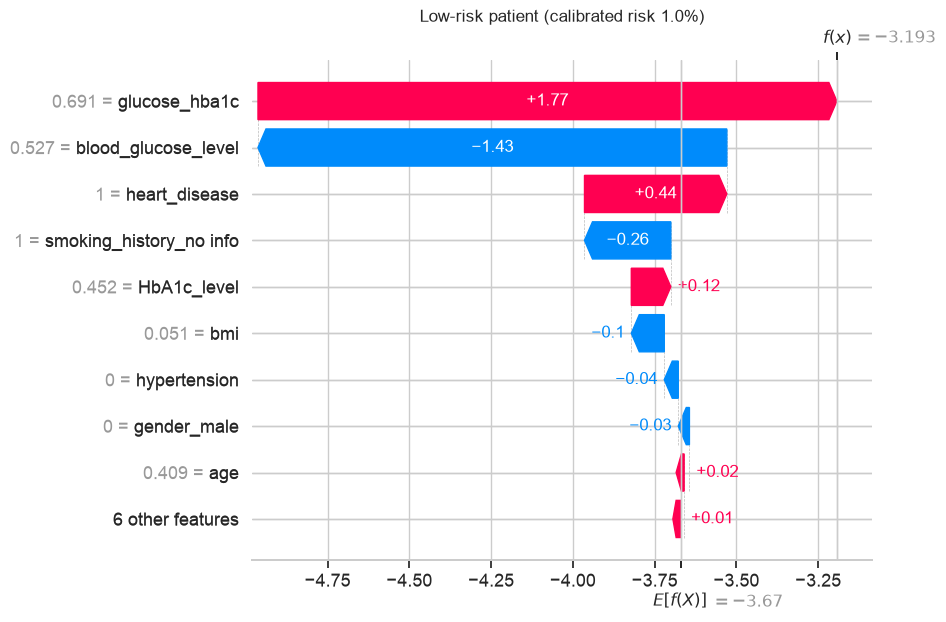

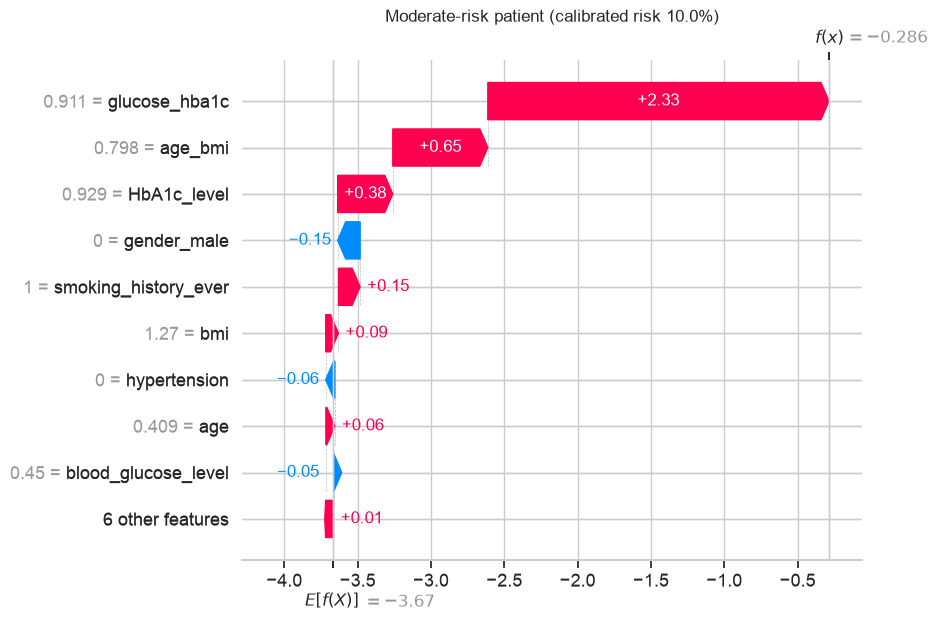

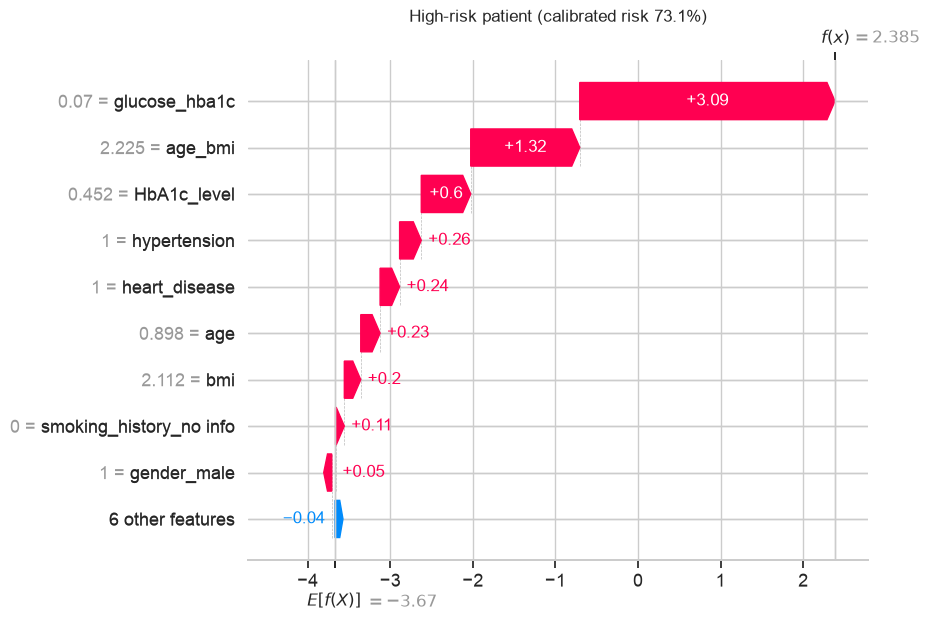

In [10]:
for label, i in examples.items():
    shap.plots.waterfall(sv[i], max_display=10, show=False)
    plt.title(f"{label.capitalize()}-risk patient (calibrated risk {p_explain[i]:.1%})")
    save_fig(plt.gcf(), FIGURES_DIR / f"shap_waterfall_{label}_risk.png")
    plt.show()

Waterfall plots start at the model's average output and show how each feature pushes this patient's score up (red) or down (blue). Feature values are shown on the standardised scale used by the model. These explanations are what a clinician would see alongside a risk score.

## 5. Subgroup performance

A model can look good overall but under-perform for particular groups. Metrics are computed on the test set at the fixed screening threshold.

In [11]:
test = add_clinical_bins(X_test.assign(**{TARGET: y_test.values}))
test["p"] = p_test

rows = []
for col in ["gender", "age_group", "bmi_cat"]:
    for level, g in test.groupby(col, observed=True):
        if g[TARGET].nunique() < 2:
            continue
        m = compute_metrics(g[TARGET], g["p"], THRESHOLD)
        rows.append({"variable": col, "group": str(level), "n": len(g), "prevalence": g[TARGET].mean(),
                     **{k: m[k] for k in ["roc_auc", "pr_auc", "sensitivity", "specificity", "precision"]}})
subgroups = pd.DataFrame(rows)
subgroups

,variable,group,n,prevalence,roc_auc,pr_auc,sensitivity,specificity,precision
0,gender,female,8378,0.0834,0.9773,0.8778,0.8484,0.9461,0.5889
1,gender,male,6042,0.0948,0.9769,0.8832,0.9127,0.9009,0.4911
2,age_group,<18,2496,0.0040,0.9944,0.8242,0.8000,1.0000,1.0000
3,age_group,18-39,3992,0.0238,0.9752,0.7996,0.7053,0.9946,0.7614
4,age_group,40-59,4344,0.1001,0.9624,0.8562,0.8276,0.9371,0.5941
5,age_group,60+,3588,0.2040,0.9564,0.8975,0.9303,0.7588,0.4971
6,bmi_cat,underweight,1260,0.0079,0.9919,0.8626,0.8000,0.9992,0.8889
7,bmi_cat,normal,3256,0.0369,0.9764,0.8182,0.7750,0.9796,0.5924
8,bmi_cat,overweight,6359,0.0791,0.9689,0.8412,0.8211,0.9284,0.4964
9,bmi_cat,obese,3545,0.1803,0.9699,0.9108,0.9421,0.8376,0.5605


In [12]:
long = subgroups.melt(id_vars=["variable", "group"], value_vars=["roc_auc", "sensitivity", "specificity"],
                      var_name="metric")
g = sns.catplot(data=long, x="group", y="value", hue="metric", col="variable", kind="bar",
                sharex=False, height=4, aspect=1.1)
g.set_titles("{col_name}")
g.set(ylim=(0.5, 1.02), xlabel="", ylabel="")
g.figure.suptitle("Test performance by subgroup (screening threshold)", y=1.04)
save_fig(g.figure, FIGURES_DIR / "subgroup_performance_test.png");

**Subgroup findings**

* Discrimination (ROC-AUC) is consistently high (≥ 0.95) across genders, age groups and BMI categories.
* **Sensitivity is lower in younger and leaner patients** (e.g. 18–39 and normal-BMI groups), where diabetes is rare. Under-18s have only ~10 test cases, so their estimates are very noisy.
* **Specificity is lower in older (60+) and obese patients**, who more often have borderline lab values — the model flags more of them for follow-up.
* Males have somewhat higher sensitivity and lower specificity than females, in line with their higher prevalence.

These patterns suggest group-specific thresholds or additional features may be needed before any deployment, and that results for small subgroups should be validated on larger, external data.

## Conclusions

1. HbA1c and glucose dominate predictions, followed by age, BMI and cardiovascular comorbidities — consistent with clinical knowledge and with the EDA.
2. Explanations are stable across global (SHAP, permutation) and transparent (logistic regression) methods.
3. Performance is broadly consistent across subgroups, with known gaps in younger and leaner patients.